In [1]:
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter, LogLocator
from scipy.ndimage import uniform_filter

from pathlib import Path

root = Path.cwd()

In [2]:
# paths
HEIGHT_FRACTIONS = root / 'data' / 'nyc21' / 'nyc21_height_fractions.tif'            # from chm_height_fractions.py
LIDAR_CANOPY = root / 'data' / 'nyc21' / 'nyc21_tree_canopy_lidar.tif'                # reference canopy %
PREDICTIONS = {                                                        # label -> OOF prediction raster
    'Spring + Summer + Fall': root / 'model_outputs' /'nyc21_canopy_from_nyc21_all_seasons_OOF_model.tif',
    'Growing season': root / 'model_outputs' /'nyc21_canopy_from_nyc21_median_season_only_OOF_model.tif',
}
OUT_FIG = root / 'figs' / 'height_band_errors.png'
OUT_CSV = root / 'models' /'nyc21'/'height_band_errors.csv'

In [3]:
MAX_TREE = 0.05          # keep pixels with tree fraction (>= 2.5 m) below this; try 0.01 to test the neighbour effect
BIN_EDGES = np.array([0, 0.01, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60])
X_MAX = 0.60
NEIGHBOR_PX = 5          # 5 x 5 pixels = 50 m window for the neighbourhood canopy
BLOCK_PX = 100           # 1 km blocks, matching the train/test split
MIN_PIXELS, MIN_BLOCKS = 200, 10
N_BOOT, SEED = 1000, 0
MODEL_STYLE = [dict(color='#7A4FA3', ls='-', marker='o'), dict(color='#D07A2A', ls='--', marker='s')]

In [4]:
def _read(path, band=None):
    with rasterio.open(path) as src:
        a = (src.read(masked=True) if band is None else src.read(band, masked=True))
        return a.astype('float32').filled(np.nan), src.transform, src.shape
 
 
def _to_pct(a):
    finite = a[np.isfinite(a)]
    return a * 100 if finite.size and finite.max() <= 1.0 else a
 
 
def _neighbour_mean(a, size):
    """Mean of the size x size window around each pixel, excluding the pixel itself (NaNs ignored)."""
    valid = np.isfinite(a)
    filled = np.where(valid, a, 0).astype('float64')
    n = size * size
    s = uniform_filter(filled, size, mode='constant') * n - filled
    c = uniform_filter(valid.astype('float64'), size, mode='constant') * n - valid
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(c > 0, s / c, np.nan)
 
 
def load_pixels():
    f, transform, shape = _read(HEIGHT_FRACTIONS)                 # lawn, shrub, short, tall, coverage
    lidar, t2, s2 = _read(LIDAR_CANOPY, 1)
    if (t2, s2) != (transform, shape):
        raise ValueError(f'{LIDAR_CANOPY} is not on the same grid as {HEIGHT_FRACTIONS}')
    lidar = _to_pct(lidar)
    neighbour = _neighbour_mean(lidar, NEIGHBOR_PX)
    preds = {}
    for name, path in PREDICTIONS.items():
        p, t3, s3 = _read(path, 1)
        if (t3, s3) != (transform, shape):
            raise ValueError(f'{path} is not on the same grid as {HEIGHT_FRACTIONS}')
        preds[name] = _to_pct(p)
 
    tree = f[2] + f[3]
    ok = (np.isfinite(f[0]) & (tree < MAX_TREE) & np.isfinite(lidar)
          & np.all([np.isfinite(p) for p in preds.values()], axis=0))
    rows, cols = np.nonzero(ok)
    d = pd.DataFrame({'x': f[1][ok] / (f[0][ok] + f[1][ok]), 'lidar': lidar[ok], 'neighbour': neighbour[ok],
                      'block': (rows // BLOCK_PX) * (shape[1] // BLOCK_PX + 1) + cols // BLOCK_PX})
    for name, p in preds.items():
        d[name] = p[ok] 
    return d[d['x'] <= X_MAX]
 
 
def block_bootstrap_bins(values, bins, blocks, n_bins):
    """Per-bin mean with a 95% CI from resampling blocks (same resamples for every variable)."""
    codes, uniq = pd.factorize(blocks)
    nb = len(uniq)
    S = np.zeros((nb, n_bins)); C = np.zeros((nb, n_bins))
    np.add.at(S, (codes, bins), values)
    np.add.at(C, (codes, bins), 1)
    W = np.random.default_rng(SEED).multinomial(nb, np.full(nb, 1 / nb), size=N_BOOT)
    with np.errstate(invalid='ignore', divide='ignore'):
        boot = (W @ S) / (W @ C)
        mean = S.sum(0) / C.sum(0)
    lo, hi = np.nanquantile(boot, [0.025, 0.975], axis=0)
    return mean, lo, hi, C.sum(0), (C > 0).sum(0)
 
 
def summarize(d):
    m1, m2 = PREDICTIONS
    n_bins = len(BIN_EDGES) - 1
    bins = np.clip(np.digitize(d['x'], BIN_EDGES[1:-1], right=True), 0, n_bins - 1)
    blocks = d['block'].to_numpy()
    stat = lambda v: block_bootstrap_bins(np.asarray(v, dtype=float), bins, blocks, n_bins)
 
    #res = {m: stat(d[m]) for m in (m1, m2)}
    res = {m: stat(d[m] - d['lidar']) for m in (m1, m2)}
    calls = {m: stat((d[m] > 0) * 100) for m in (m1, m2)}
    diff = stat((d[m2] - d['lidar']).abs() - (d[m1] - d['lidar']).abs())
    lid, nbr = stat(d['lidar']), stat(d['neighbour'])
 
    n, nblk = res[m1][3], res[m1][4]
    rows = []
    for k in range(n_bins):
        r = {'bin': f'{BIN_EDGES[k]*100:g}–{BIN_EDGES[k+1]*100:g}%', 'bin_lo': BIN_EDGES[k], 'bin_hi': BIN_EDGES[k + 1],
             'x': (BIN_EDGES[k] + BIN_EDGES[k + 1]) / 2, 'n_pixels': int(n[k]), 'n_blocks': int(nblk[k]),
             'plotted': bool(n[k] >= MIN_PIXELS and nblk[k] >= MIN_BLOCKS),
             'lidar_canopy': lid[0][k], f'neighbour_canopy_{NEIGHBOR_PX * 10}m': nbr[0][k]}
        for m in (m1, m2):
            r[f'{m} | mean'], r[f'{m} | lo'], r[f'{m} | hi'] = (res[m][i][k] for i in range(3))
            r[f'{m} | % called canopy'] = calls[m][0][k]
        r['diff | mean'], r['diff | lo'], r['diff | hi'] = (diff[i][k] for i in range(3))
            
        rows.append(r)
    return pd.DataFrame(rows)
 
def plot(t, fname=None):
    """Grouped bar chart: one group per shrub-share bin (bins evenly spaced and labelled, so their
    different widths are explicit), one bar per model, 95% block-bootstrap CIs as error bars,
    pixel count under each bin label, and a lawn -> shrub arrow under the axis."""
    m1, m2 = PREDICTIONS
    t = t[t.plotted].reset_index(drop=True)
    n_bins = len(t)
    x = np.arange(n_bins)
    w = 0.38
 
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for i, (m, st) in enumerate(zip((m1, m2), MODEL_STYLE)):
        mean = t[f'{m} | mean']
        err = np.vstack([mean - t[f'{m} | lo'], t[f'{m} | hi'] - mean])
        ax.bar(x + (i - 0.5) * w, mean, w, color=st['color'], edgecolor='white', lw=1, label=f'{m} Model')
        ax.errorbar(x + (i - 0.5) * w, mean, yerr=err, fmt='none', ecolor='0.25', elinewidth=1, capsize=3)
 
    labels = [f"{lo*100:g}–{hi*100:g}%\nn = {n:,}" for lo, hi, n in zip(t['bin_lo'], t['bin_hi'], t['n_pixels'])]
    ax.set_title('Overprediction of Tree Canopy in Shrub/Lawn Pixels')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlim(-0.6, n_bins - 0.4)
    #ax.set_ylabel('Predicted canopy (%)\n(true canopy ≈ 0%)')
    ax.set_ylabel('Mean Residual\n(Predicted - Lidar % Tree Canopy)')
    ax.set_xlabel('Bins: Shrub % per Pixel', labelpad=4)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
 
    # lawn -> shrub gradient arrow below the axis label
    lo_end, hi_end = t['bin_lo'].iloc[0], t['bin_hi'].iloc[-1]
    left_txt = f'{lo_end * 100:g}% shrub, {(1 - lo_end) * 100:g}% lawn'
    right_txt = f'{hi_end * 100:g}% shrub, {(1 - hi_end) * 100:g}% lawn'
    # positioned relative to the x-axis label (x in axes fraction, y in units of the label's height)
    coords = ('axes fraction', ax.xaxis.label)
    y_arrow = -0.9
    ax.annotate(left_txt, xy=(0.0, y_arrow), xycoords=coords, ha='left', va='center',
                fontsize=9, color='0.25', annotation_clip=False)
    ax.annotate(right_txt, xy=(1.0, y_arrow), xycoords=coords, ha='right', va='center',
                fontsize=9, color='0.25', annotation_clip=False)
    ax.annotate('', xy=(0.80, y_arrow), xytext=(0.20, y_arrow), xycoords=coords, textcoords=coords,
                arrowprops=dict(arrowstyle='-|>', color='0.45', lw=1.2), annotation_clip=False)
 
    plt.tight_layout()
    plt.savefig(fname or OUT_FIG, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()



In [5]:
d = load_pixels()
print(f'{len(d):,} tree-free vegetated pixels (tree fraction < {MAX_TREE:g}) in {d["block"].nunique():,} blocks')
t = summarize(d)
t.to_csv(OUT_CSV, index=False)
m1, m2 = PREDICTIONS
show = ['bin', 'n_pixels', 'lidar_canopy', f'neighbour_canopy_{NEIGHBOR_PX * 10}m',
        f'{m1} | mean', f'{m2} | mean', f'{m1} | % called canopy', f'{m2} | % called canopy', 'diff | mean']
print(t[show].round(2).to_string(index=False))


416,589 tree-free vegetated pixels (tree fraction < 0.05) in 942 blocks
   bin  n_pixels  lidar_canopy  neighbour_canopy_50m  Spring + Summer + Fall | mean  Growing season | mean  Spring + Summer + Fall | % called canopy  Growing season | % called canopy  diff | mean
  0–1%    376216          0.18                  7.52                           5.10                   7.04                                     20.53                             24.88         1.92
 1–10%     29381          3.67                 23.51                          16.41                  20.54                                     65.98                             68.20         3.96
10–15%      3534          4.57                 20.75                          17.79                  21.73                                     71.70                             72.61         3.79
15–20%      2206          4.33                 20.93                          19.51                  23.87                                     7

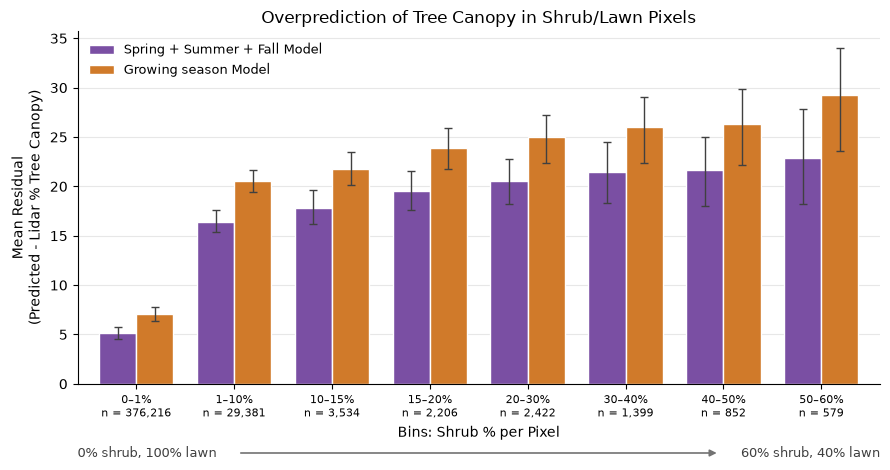

In [6]:
plot(t)

In [52]:
def plot(t, fname=None):
    """Grouped bar chart: one group per shrub-share bin (bins evenly spaced and labelled, so their
    different widths are explicit), one bar per model, 95% block-bootstrap CIs as error bars,
    pixel count under each bin label, and a lawn -> shrub arrow under the axis."""
    m1, m2 = PREDICTIONS
    t = t[t.plotted].reset_index(drop=True)
    n_bins = len(t)
    x = np.arange(n_bins)
    w = 0.38
 
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for i, (m, st) in enumerate(zip((m1, m2), MODEL_STYLE)):
        mean = t[f'{m} | mean']
        err = np.vstack([mean - t[f'{m} | lo'], t[f'{m} | hi'] - mean])
        ax.bar(x + (i - 0.5) * w, mean, w, color=st['color'], edgecolor='white', lw=1, label=f'{m} Model')
        ax.errorbar(x + (i - 0.5) * w, mean, yerr=err, fmt='none', ecolor='0.25', elinewidth=1, capsize=3)
 
    labels = [f"{lo*100:g}–{hi*100:g}%\nn = {n:,}" for lo, hi, n in zip(t['bin_lo'], t['bin_hi'], t['n_pixels'])]
    ax.set_title('Overprediction of Tree Canopy in Shrub/Lawn Pixels')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlim(-0.6, n_bins - 0.4)
    ax.set_ylabel('Predicted canopy (%)\n(true canopy ≈ 0%)')
    ax.set_xlabel('Bins: Shrub % per Pixel', labelpad=4)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
 
    # lawn -> shrub gradient arrow below the axis label
    lo_end, hi_end = t['bin_lo'].iloc[0], t['bin_hi'].iloc[-1]
    left_txt = f'{lo_end * 100:g}% shrub, {(1 - lo_end) * 100:g}% lawn'
    right_txt = f'{hi_end * 100:g}% shrub, {(1 - hi_end) * 100:g}% lawn'
    # positioned relative to the x-axis label (x in axes fraction, y in units of the label's height)
    coords = ('axes fraction', ax.xaxis.label)
    y_arrow = -0.9
    ax.annotate(left_txt, xy=(0.0, y_arrow), xycoords=coords, ha='left', va='center',
                fontsize=9, color='0.25', annotation_clip=False)
    ax.annotate(right_txt, xy=(1.0, y_arrow), xycoords=coords, ha='right', va='center',
                fontsize=9, color='0.25', annotation_clip=False)
    ax.annotate('', xy=(0.80, y_arrow), xytext=(0.20, y_arrow), xycoords=coords, textcoords=coords,
                arrowprops=dict(arrowstyle='-|>', color='0.45', lw=1.2), annotation_clip=False)
 
    plt.tight_layout()
    plt.savefig(fname or OUT_FIG, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

In [19]:
BLOCK_PX = 100          # 1 km blocks at 10 m, matching the train/test split
PURE = 0.02             # "no trees" = tree fraction < 5%; "fully treed" = lawn + shrub < 5%
BIN_EDGES = np.linspace(0, 1, 11)
MIN_PIXELS, MIN_BLOCKS = 500, 10       # bins with fewer are not plotted
N_BOOT, SEED = 1000, 0
MODEL_STYLE = [dict(color='#7A4FA3', ls='-'), dict(color='#D07A2A', ls='--')]

In [5]:
def _read(path, band=1):
    with rasterio.open(path) as src:
        a = src.read(band, masked=True).astype('float32').filled(np.nan)
        return a, src.transform, src.shape


def _to_pct(a):
    finite = a[np.isfinite(a)]
    return a * 100 if finite.size and finite.max() <= 1.0 else a


def load_pixels():
    """One row per fully vegetated pixel: fractions, lidar canopy, both predictions, block id."""
    with rasterio.open(HEIGHT_FRACTIONS) as src:
        f = src.read().astype('float32')                     # lawn, shrub, short_tree, tall_tree, coverage
        shape, transform = src.shape, src.transform
    lidar, t2, s2 = _read(LIDAR_CANOPY)
    preds = {}
    for name, path in PREDICTIONS.items():
        p, t3, s3 = _read(path)
        if s3 != shape or t3 != transform:
            raise ValueError(f'{path} is not on the same grid as {HEIGHT_FRACTIONS}')
        preds[name] = _to_pct(p)
    if s2 != shape or t2 != transform:
        raise ValueError(f'{LIDAR_CANOPY} is not on the same grid as {HEIGHT_FRACTIONS}')
    lidar = _to_pct(lidar)

    ok = np.isfinite(f[0]) & np.isfinite(lidar) & np.all([np.isfinite(p) for p in preds.values()], axis=0)
    rows, cols = np.nonzero(ok)
    df = pd.DataFrame({'lawn': f[0][ok], 'shrub': f[1][ok], 'short_tree': f[2][ok], 'tall_tree': f[3][ok],
                       'lidar': lidar[ok],
                       'block': (rows // BLOCK_PX) * (shape[1] // BLOCK_PX + 1) + cols // BLOCK_PX})
    for name, p in preds.items():
        df[name] = p[ok]
    return df


def select_gradients(df):
    """Pixels and x-values for the two gradients."""
    tree, low = df['short_tree'] + df['tall_tree'], df['lawn'] + df['shrub']
    a = df[tree < PURE].copy() # less than 5% tree
    a['x'] = a['shrub'] / (a['lawn'] + a['shrub'])
    b = df[low < PURE].copy() # less than 5% shrub/grass
    b['x'] = b['short_tree'] / (b['short_tree'] + b['tall_tree'])
    return {'A': a, 'B': b}


def block_bootstrap_bins(values, bins, blocks, n_bins, n_boot=N_BOOT, seed=SEED):
    """Mean of `values` per bin, with a 95% CI from resampling blocks.

    Works on per-(block, bin) sums and counts, so each resample is a matrix product.
    The same seed gives the same block resamples for every variable, so CIs are paired.
    """
    codes, uniq = pd.factorize(blocks)
    nb = len(uniq)
    S = np.zeros((nb, n_bins)); C = np.zeros((nb, n_bins))
    np.add.at(S, (codes, bins), values)
    np.add.at(C, (codes, bins), 1)
    W = np.random.default_rng(seed).multinomial(nb, np.full(nb, 1 / nb), size=n_boot)   # (n_boot, nb)
    with np.errstate(invalid='ignore', divide='ignore'):
        boot = (W @ S) / (W @ C)
        mean = S.sum(0) / C.sum(0)
    lo, hi = np.nanquantile(boot, [0.025, 0.975], axis=0)
    return mean, lo, hi, C.sum(0), (C > 0).sum(0)


def summarize(grads):
    """Per-gradient, per-bin table of means, CIs, paired differences and classifier hit rates."""
    m1, m2 = PREDICTIONS                     # m1 = three-season, m2 = growing season
    n_bins = len(BIN_EDGES) - 1
    centers = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2
    out = []
    for g, d in grads.items():
        bins = np.clip(np.digitize(d['x'], BIN_EDGES) - 1, 0, n_bins - 1)
        res = {}
        for m in (m1, m2):
            y = d[m] if g == 'A' else d[m] - d['lidar']           # A: predicted canopy; B: residual
            res[m] = block_bootstrap_bins(y.to_numpy(), bins, d['block'].to_numpy(), n_bins)
            # share of pixels the classifier called canopy (prediction > 0)
            res[m + '_canopy_call'] = block_bootstrap_bins((d[m] > 0).to_numpy(float) * 100, bins,
                                                           d['block'].to_numpy(), n_bins)
        diff = (d[m2] - d['lidar']).abs() - (d[m1] - d['lidar']).abs()
        res['diff'] = block_bootstrap_bins(diff.to_numpy(), bins, d['block'].to_numpy(), n_bins)
        lid = block_bootstrap_bins(d['lidar'].to_numpy(), bins, d['block'].to_numpy(), n_bins)

        n, nblk = res['diff'][3], res['diff'][4]
        keep = (n >= MIN_PIXELS) & (nblk >= MIN_BLOCKS)
        for k in range(n_bins):
            row = {'gradient': g, 'bin_lo': BIN_EDGES[k], 'bin_hi': BIN_EDGES[k + 1], 'x': centers[k],
                   'n_pixels': int(n[k]), 'n_blocks': int(nblk[k]), 'plotted': bool(keep[k]),
                   'mean_lidar_canopy': lid[0][k]}
            for m in (m1, m2):
                row[f'{m} | mean'], row[f'{m} | lo'], row[f'{m} | hi'] = (res[m][i][k] for i in range(3))
                row[f'{m} | % called canopy'] = res[m + '_canopy_call'][0][k]
            row['diff | mean'], row['diff | lo'], row['diff | hi'] = (res['diff'][i][k] for i in range(3))
            out.append(row)
    return pd.DataFrame(out)

In [20]:
df = load_pixels()

In [21]:
grads = select_gradients(df)

In [22]:
for g, d in grads.items():
        print(f'gradient {g}: {len(d):,} pixels in {d["block"].nunique():,} blocks, '
              f'mean lidar canopy = {d["lidar"].mean():.1f}%')

gradient A: 397,342 pixels in 933 blocks, mean lidar canopy = 0.3%
gradient B: 461,512 pixels in 913 blocks, mean lidar canopy = 99.8%


In [23]:
table = summarize(grads)

In [14]:
table.to_csv(OUT_CSV, index=False)

In [15]:
def plot(table, fname=None):
    m1, m2 = PREDICTIONS
    fig, axes = plt.subplots(3, 2, figsize=(10, 8.5), sharex='col',
                             gridspec_kw={'height_ratios': [3, 2, 1]})
    titles = {'A': 'A. Lawn → shrub (no trees; true canopy ≈ 0%)',
              'B': 'B. Tall → short trees (fully treed; true canopy ≈ 100%)'}
    ylab = {'A': 'Predicted canopy (%)', 'B': 'Predicted − lidar canopy\n(percentage points)'}
    xlab = {'A': 'Shrub share of non-tree vegetation (0.5–2.5 m)',
            'B': 'Short-tree share of tree cover (2.5–5 m)'}

    for c, g in enumerate(['A', 'B']):
        t = table[(table.gradient == g) & table.plotted]
        x = t['x'] * 100
        ax = axes[0, c]
        for m, st in zip((m1, m2), MODEL_STYLE):
            ax.plot(x, t[f'{m} | mean'], lw=2, marker='o', ms=4, label=m, **st)
            ax.fill_between(x, t[f'{m} | lo'], t[f'{m} | hi'], color=st['color'], alpha=0.18, lw=0)
        ax.axhline(0, color='0.4', lw=0.8)
        ax.set_title(titles[g], loc='left', fontsize=10)
        ax.set_ylabel(ylab[g])

        ax = axes[1, c]
        ax.plot(x, t['diff | mean'], color='0.15', lw=2, marker='o', ms=4)
        ax.fill_between(x, t['diff | lo'], t['diff | hi'], color='0.15', alpha=0.15, lw=0)
        ax.axhline(0, color='0.4', lw=0.8)
        ax.set_ylabel('|error| growing season −\n|error| three-season (pp)')

        ax = axes[2, c]
        ax.bar(x, t['n_pixels'], width=8, color='0.7')
        ax.set_ylabel('Pixels')
        ax.set_xlabel(xlab[g])
        ax.set_xlim(0, 100)
        for a in axes[:, c]:
            a.grid(axis='y', alpha=0.3)
            for side in ('top', 'right'):
                a.spines[side].set_visible(False)

    axes[0, 0].legend(frameon=False, fontsize=9)
    axes[1, 0].text(0.01, 0.95, '> 0: three-season model more accurate', transform=axes[1, 0].transAxes,
                    fontsize=8, color='0.35', va='top')
    plt.tight_layout()
    #plt.savefig(fname or OUT_FIG, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

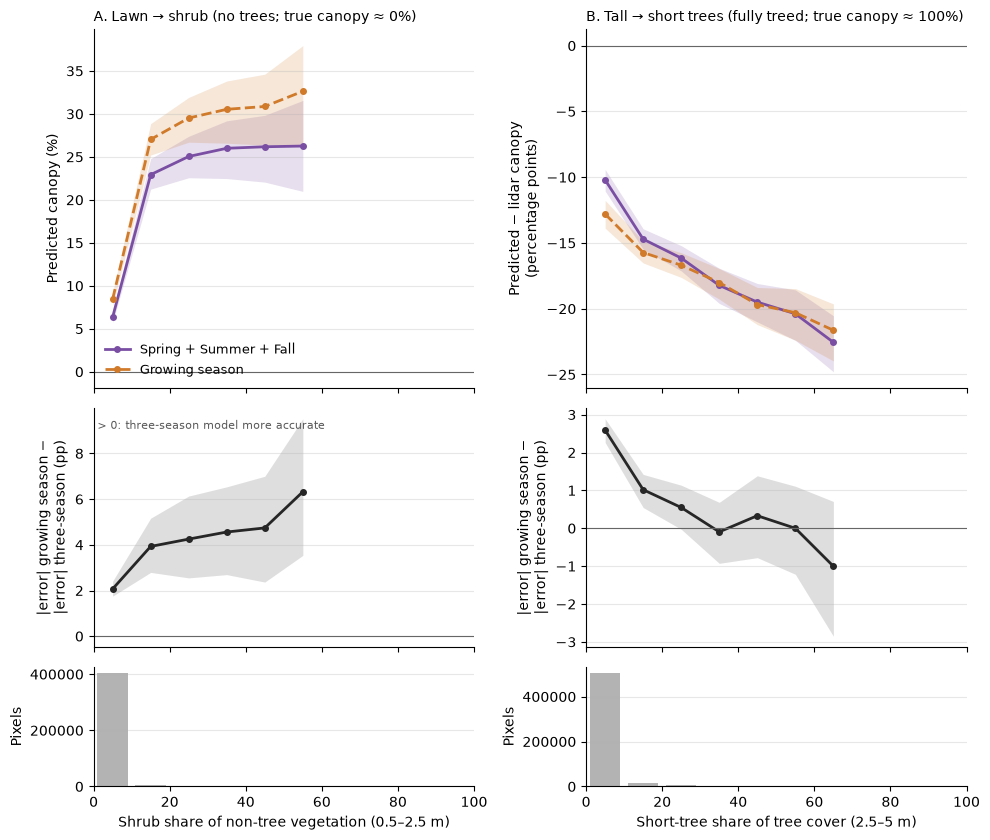

In [16]:
plot(table)